# IRWA Final Project. Part 1: Text Processing and Exploratory Data Analysis

Course: Information Retrieval and Web Analytics (IRWA)
Group members: Sergi Cases, Julia Garcia, Martí Casas


Project Overview

This notebook presents the first part of the IRWA Final Project, focused on preparing and analyzing a dataset of fashion products from Flipkart.

The main objective is to transform the original dataset into a structured and searchable corpus, while exploring its characteristics to support the development of the information retrieval system in the following parts of the project.

The notebook is divided into two main sections:

1. Data Preparation

* Load and inspect the original dataset.
* Pre-process textual fields through tokenization, normalization, stop word removal and stemming.
* Analyze categorical, numerical and boolean fields to determine how they should be handled.
* Build and export the processed corpus for the retrieval system.
* Validate the preprocessing pipeline using the provided queries and relevance labels.

2. Exploratory Data Analysis (EDA)

* Analyze document lengths, vocabulary size and word frequency distributions.
* Explore the most frequent terms and visualize them using word clouds.
* Examine product categories, brands, sellers and attributes.
* Analyze prices, discounts, ratings and stock availability.
* Identify duplicated titles and potential data quality issues.
* Explore named entities using Named Entity Recognition (NER).
* Summarize the main findings and their implications for the search engine.

The resulting processed corpus will be used in Part 2 to build the inverted index and implement the retrieval and ranking methods.

In [44]:
import json
import math
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize
from wordcloud import WordCloud

nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 30)

In [45]:
# Define the paths for the input and output files
DATA_DIR = "./"
CORPUS_PATH = DATA_DIR + "fashion_products_dataset.json"
VALIDATION_PATH = DATA_DIR + "validation_labels.csv"
OUTPUT_PATH = DATA_DIR + "processed_corpus.json"

# PART 1: Data preparation

## 1.1 Load the corpus and first look

In [46]:
# Load the dataset and check its structure
with open(CORPUS_PATH, "r", encoding="utf-8") as f:
    raw_docs = json.load(f)

df = pd.DataFrame(raw_docs)
print("Number of documents:", len(df))
print("Number of fields:", len(df.columns))
print("Fields:", list(df.columns))

Number of documents: 28080
Number of fields: 17
Fields: ['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']


In [47]:
df.head(3)

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,69% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-10...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,66% off,[https://rukminim1.flixcart.com/image/128/128/kfyasnk0/track-pant/g/5/y/s-19...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets':...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,68% off,[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/e/c/s/xl-1...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...


In [48]:
# Example of one full document
print(json.dumps(raw_docs[0], indent=2, ensure_ascii=False)[:2000])

{
  "_id": "fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a",
  "actual_price": "2,999",
  "average_rating": "3.9",
  "brand": "York",
  "category": "Clothing and Accessories",
  "crawled_at": 1612987911000,
  "description": "Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India",
  "discount": "69% off",
  "images": [
    "https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70",
    "https://rukminim1.flixcart.com/image/128/128/jr58l8w0/track-pant/w/d/a/l-1005combo8-yorker-original-imafczg3pgtxgraq.jpeg?q=70"
  ],
  "out_of_stock": false,
  "pid": "TKPFCZ9EA7H5FYZH",
  "product_details": [
    {
      "Style Code": "1005COMBO2"
    },
    {
      "Closure": "Elastic"
    },
    {
      "Pockets": "Side Pockets"
    },
    {
      "Fabric": "Cotton Blend"
    },
    {
      "Pattern": "Solid"


As we can observe from the example printed above, most fields are stored as strings, including prices and discounts. However, some fields have different formats, such as out_of_stock (boolean), product_details ( list of dictionaries), images (list of URLs) and crawled_at (timestamp). We can also see that some missing values are represented as empty strings, so we will consider both when checking for missing data.

In [49]:
# Check if a value is missing or empty (we consider a value missing if it is None, NaN, an empty string or an empty list)
def is_empty(value):
    """True if a value is missing: None, NaN, empty string or empty list."""
    if value is None:
        return True
    if isinstance(value, float) and math.isnan(value):
        return True
    if isinstance(value, (str, list)) and len(value) == 0:
        return True
    return False


missing = pd.DataFrame({
    "missing_docs": [df[col].apply(is_empty).sum() for col in df.columns],
}, index=df.columns)
missing["missing_%"] = (100 * missing["missing_docs"] / len(df)).round(2)
missing.sort_values("missing_docs", ascending=False)

,missing_docs,missing_%
description,11150,39.71
average_rating,2261,8.05
brand,2009,7.15
seller,1643,5.85
discount,855,3.04
actual_price,777,2.77
images,772,2.75
selling_price,2,0.01
product_details,0,0.00
title,0,0.00


As we can see from the table, description has the highest percentage of missing values (39.71%), followed by average_rating (8.05%) and brand (7.15%). Since many products do not have a description, we will need to take this into account during text preprocessing. However, all products have the title and a pid, which are important for our search engine.

In [50]:
# Check the number of unique values for pid, _id and title
print("Unique pid:  ", df["pid"].nunique(), "of", len(df))
print("Unique _id:  ", df["_id"].nunique(), "of", len(df))
print("Unique title:", df["title"].nunique(), "of", len(df))

Unique pid:   28080 of 28080
Unique _id:   28080 of 28080
Unique title: 5953 of 28080


Both pid and _id are unique for every product, while title has only 5.953 unique values. Therefore, we will use pid as the document identifier for indexing and evaluation in Part 2.

## 1.2 Text pre-processing (title and description)

We apply the following preprocessing steps to the title and description fields. The same steps will also be applied to the queries to ensure that the terms are processed consistently.

| # | Step | Why |
|---|------|-----|
| 1 | **Lowercasing** | Convert all text to lowercase to avoid differences between uppercase and lowercase words. |
| 2 | **Remove non-ASCII characters and URLs** | Remove URLs and special characters that may introduce noise. |
| 3 | **Domain normalization** | Normalize common fashion-related terms, such as t-shirt and tshirt, to the same form. |
| 4 | **Remove punctuation** | Replace punctuation with spaces to separate words correctly. |
| 5 | **Tokenization** | Split the text into individual words using NLTK. |
| 6 | **Remove numbers and single-character tokens** | Remove tokens that are not considered useful for text retrieval. |
| 7 | **Remove stop words** | Remove common English words that do not add much meaning to the text. |
| 8 | **Stemming** | Reduce words to their stems using PorterStemmer. |

We also keep the original text to display the products in the search results.

In [51]:
stemmer = PorterStemmer()
STOP_WORDS = set(stopwords.words("english"))

# Normalize common spelling variations in fashion products
NORMALIZATION_RULES = [
    (r"\bt[\s-]?shirts?\b", "tshirt"),
    (r"\btees?\b", "tshirt"),
    (r"\bmen'?s\b", "men"),
    (r"\bwomen'?s\b", "women"),
    (r"\bboy'?s\b", "boys"),
    (r"\bgirl'?s\b", "girls"),
    (r"\b(slim|regular|skinny|relaxed|loose)fit\b", r"\1 fit"),
    (r"\bpolycotton\b", "poly cotton"),
]

# Clean the text before tokenization
def clean_text(text):
    """Steps 1-4: lowercase, remove URLs and non-ASCII, normalize variants, remove punctuation."""
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = text.encode("ascii", errors="ignore").decode()
    for pattern, replacement in NORMALIZATION_RULES:
        text = re.sub(pattern, replacement, text)
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)
    return text

# Apply the preprocessing steps and return the processed words
def build_terms(text):
    """Full pre-processing pipeline: returns the list of processed terms of a text."""
    if not isinstance(text, str) or text.strip() == "":
        return []
    text = clean_text(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]
    tokens = [t for t in tokens if t not in STOP_WORDS]
    tokens = [stemmer.stem(t) for t in tokens]
    return tokens

In [52]:
# Check how the preprocessing steps change a product description
example = df.loc[0, "description"]
print("ORIGINAL:\n", example, "\n")

step = clean_text(example)
print("1-4. CLEANED TEXT (lowercase, no URLs/non-ASCII, normalized, no punctuation):\n", step, "\n")

step = word_tokenize(step)
print("5. TOKENS:\n", step, "\n")

step = [t for t in step if t.isalpha() and len(t) > 1]
print("6. WITHOUT NUMBERS / SINGLE-CHARACTER TOKENS:\n", step, "\n")

step = [t for t in step if t not in STOP_WORDS]
print("7. WITHOUT STOP WORDS:\n", step, "\n")

step = [stemmer.stem(t) for t in step]
print("8. STEMMED (final terms):\n", step)

ORIGINAL:
 Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India 

1-4. CLEANED TEXT (lowercase, no URLs/non-ASCII, normalized, no punctuation):
 yorker trackpants made from 100  rich combed cotton giving it a rich look designed for comfort skin friendly fabric itch free waistband   great for all year round use proudly made in india 

5. TOKENS:
 ['yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india'] 

6. WITHOUT NUMBERS / SINGLE-CHARACTER TOKENS:
 ['yorker', 'trackpants', 'made', 'from', 'rich', 'combed', 'cotton', 'giving', 'it', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistb

In [53]:
# Check how different product names are normalized
for text in ["Men's Slim Fit T-Shirt", "Womens full-sleeve TEE", "Boy's printed t shirts", "Slimfit Polycotton jeans"]:
    print(f"{text:30} -> {build_terms(text)}")

Men's Slim Fit T-Shirt         -> ['men', 'slim', 'fit', 'tshirt']
Womens full-sleeve TEE         -> ['women', 'full', 'sleev', 'tshirt']
Boy's printed t shirts         -> ['boy', 'print', 'tshirt']
Slimfit Polycotton jeans       -> ['slim', 'fit', 'poli', 'cotton', 'jean']


In [54]:
# Apply the pipeline to title and description of every document
df["title_terms"] = df["title"].apply(build_terms)
df["description_terms"] = df["description"].apply(build_terms)
df[["title", "title_terms", "description", "description_terms"]].head()

,title,title_terms,description,description_terms
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,"[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]",Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,"[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]",Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,"[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf..."
3,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,"[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf..."
4,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]",Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,"[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf..."


Why stemming instead of lemmatiation?

We decided to use Porter stemming because it is simple and fast, and it helps group different forms of the same word. For example, printed and prints are both reduced to rint. This can improve recall when searching for products, although sometimes different words may be reduced to the same stem.

## 1.3 Categorical fields: category, sub_category, brand, product_details, seller


In this section, we analyze the categorical fields to decide whether they should be combined into a single text field or indexed separately. To make this decision, we first examine the values and characteristics of each field.

In [55]:
# Convert product details into a single dictionary
def flatten_details(details):
    """Turns [{'Fabric': 'Cotton'}, {'Color': 'Blue'}] into {'Fabric': 'Cotton', 'Color': 'Blue'}."""
    flat = {}
    if isinstance(details, list):
        for item in details:
            for key, value in item.items():
                flat[key] = value
    return flat


df["details_dict"] = df["product_details"].apply(flatten_details)

# Analyze the categorical fields
rows = []
for col in ["category", "sub_category", "brand", "seller"]:
    values = df[col].replace("", np.nan).dropna()
    rows.append({
        "field": col,
        "distinct_values": values.nunique(),
        "most_common_value": values.value_counts().index[0],
        "share_of_most_common_%": round(100 * values.value_counts().iloc[0] / len(df), 2),
        "empty_%": round(100 * (df[col] == "").sum() / len(df), 2),
    })
pd.DataFrame(rows)

,field,distinct_values,most_common_value,share_of_most_common_%,empty_%
0,category,4,Clothing and Accessories,96.57,0.00
1,sub_category,24,Topwear,54.52,0.00
2,brand,324,ECKO Unl,3.39,7.15
3,seller,534,RetailNet,5.02,5.85


In [56]:
detail_keys = Counter(key for d in df["details_dict"] for key in d)
print("Different keys in product_details:", len(detail_keys))
pd.DataFrame(detail_keys.most_common(30), columns=["key", "num_docs"])

Different keys in product_details: 127


,key,num_docs
0,Fabric,25959
1,Style Code,25763
2,Pattern,25692
3,Fabric Care,21830
4,Suitable For,19139
5,Sleeve,18861
6,Pack of,17953
7,Type,17394
8,Ideal For,16983
9,Fit,16808


Observations:

- Category has only 4 distinct values, with 96.57% of the products belonging to  "Clothing and Accessories". Therefore, it is not very useful for distinguishing products.

- Sub_category has 24 distinct values and provides more specific information about the products.

- Brand has hundreds of values, so it is very distinctive, and users *do* search by brand ("ecko jeans"). Note that many brand names are truncated in the dataset (e.g. "ECKO Unl", "Free Authori").

- Seller is also distinctive, but it describes the shop, not the product. Users almost never search by seller, and a seller name such as "RetailNet" adds terms that would create false matches.

- Product_details contains exactly the attributes users search for: *Fabric*, *Color*, *Sleeve*, *Fit*, *Ideal For* (Men/Women), *Pattern*, *Neck Type*... Some keys are not useful for search: *Style Code* and *Model Name* (internal codes), *Pack of*, *Reversible*, *Sales Package*, *Fabric Care*, *Country of Origin*, *Size*, which are mostly codes, numbers or the same value for every product.

Based on these observations, some categorical fields may be more useful as filters, while others could provide additional terms for indexing.

In [57]:
validation = pd.read_csv(VALIDATION_PATH)
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}

print(validation.shape)
print("All validation pids are in the corpus:", validation["pid"].isin(df["pid"]).all())
validation.groupby(["query_id", "labels"]).size().unstack()

(40, 4)
All validation pids are in the corpus: True


labels,0,1
query_id,,
1,7,13
2,10,10


In [58]:
# Product details excluded from text indexing
EXCLUDED_DETAIL_KEYS = {
    "Style Code", "Model Name", "Pack of", "Reversible", "Sales Package",
    "Fabric Care", "Country of Origin", "Size", "Other Details",
}

# Combine the selected product details into a single text
def details_to_text(details_dict):
    """Joins the useful values of product_details into one text, e.g. 'Cotton Blend Solid Men Blue'."""
    values = [str(v) for k, v in details_dict.items() if k not in EXCLUDED_DETAIL_KEYS]
    return " ".join(values)


df["details_text"] = df["details_dict"].apply(details_to_text)
df["details_terms"] = df["details_text"].apply(build_terms)
df["brand_terms"] = df["brand"].apply(build_terms)

# Check where query terms appear in the relevant documents
docs_by_pid = df.set_index("pid")
for qid, query in QUERIES.items():
    relevant_pids = validation[(validation["query_id"] == qid) & (validation["labels"] == 1)]["pid"]
    rows = []
    for term in build_terms(query):
        row = {"query_term": term}
        for field in ["title_terms", "description_terms", "details_terms", "brand_terms"]:
            has_term = [term in docs_by_pid.loc[pid, field] for pid in relevant_pids]
            row[field] = f"{100 * np.mean(has_term):.0f}%"
        rows.append(row)
    print(f"\nQuery {qid}: '{query}' ({len(relevant_pids)} relevant docs)")
    display(pd.DataFrame(rows))


Query 1: 'women full sleeve sweatshirt cotton' (13 relevant docs)


,query_term,title_terms,description_terms,details_terms,brand_terms
0,women,100%,46%,0%,0%
1,full,100%,46%,100%,0%
2,sleev,100%,38%,100%,0%
3,sweatshirt,100%,62%,31%,0%
4,cotton,0%,100%,92%,0%



Query 2: 'men slim jeans blue' (10 relevant docs)


,query_term,title_terms,description_terms,details_terms,brand_terms
0,men,70%,0%,70%,0%
1,slim,50%,50%,10%,0%
2,jean,100%,60%,80%,0%
3,blue,100%,30%,100%,0%


From the results above, we can see that no single field contains all the query terms.

- For query 1, cotton never appears in the title of the relevant sweatshirts (0%), but it appears in the description (100%) and in product_details (92%, *Fabric: Cotton Blend / Pure Cotton / Polycotton*). Instead, *women* is only in the title, because these products have no *Ideal For* attribute.

- For query 2, *slim* is in only half of the titles, and *men* is in 70% of the titles and of the details (some relevant products are actually women's jeans, see 1.6). *Blue* is always in product_details (*Color*).

- The brand never contains query terms, as expected for these generic queries (it matters for brand queries like "ecko jeans").

This shows that combining information from different fields is important to retrieve relevant products.

### Decision

We use a **hybrid approach**:

| Field | Decision | Reason |
|---|---|---|
| title, description | Merged into the main searchable text | Main textual content of the product. |
| product_details | Merged into the main text (only the useful keys) and also kept as a key-value dictionary | Contains the attributes users search for (fabric, colour, fit, sleeve, gender). Codes and non-descriptive keys are excluded to avoid noise. The dictionary allows attribute filters later (e.g. Color = Blue). |
| brand | Merged into the main text and kept as a separate field | Highly distinctive and users search by brand. The separate field allows brand filters. |
| category, sub_category | Separate fields (not in the main text) | Very low distinctiveness (IDF ≈ 0) and users do not type them; they work better as filters/facets or for a boost. |
| seller | Separate field (not in the main text) | Describes the shop, not the product; would create false matches. Useful for filters or for a seller-based score. |

We also store each field's terms separately (title_terms, description_terms, details_terms, brand_terms), so that in Parts 2-3 we can give different weights to each field (e.g. a match in the title counts more than in the description) without pre-processing again.

### Pros and cons of each approach

| Approach | Pros | Cons |
|---|---|---|
| Single merged text field | Simple: one inverted index, one TF-IDF. Maximizes recall, essential for AND queries because a term can be found in any field. | Loses where each term comes from, so all fields count the same. Low-distinctiveness values (category) add noise and inflate document length; a word in the seller name can create false matches. |
| Separate fields (one index per field) | Allows field weighting (title > details > description), field-specific queries and filters. Each field keeps its own statistics. | More complex: several indexes, and we have to decide how to combine scores. With AND semantics, requiring all terms *in the same field* would destroy recall. |
| Hybrid (our choice) | Recall of the merged field, plus separate fields for filtering, faceting and weighting. | Some redundancy in storage (brand and details are stored twice) and slightly more code. |

In [59]:
# Combine the main searchable fields
df["all_terms"] = df["title_terms"] + df["description_terms"] + df["details_terms"] + df["brand_terms"]

# Process category, subcategory and seller separately
df["category_terms"] = df["category"].apply(build_terms)
df["sub_category_terms"] = df["sub_category"].apply(build_terms)
df["seller_terms"] = df["seller"].apply(build_terms)

df[["title", "details_text", "brand", "all_terms"]].head()

,title,details_text,brand,all_terms
0,Solid Women Multicolor Track Pants,Elastic Side Pockets Cotton Blend Solid Multicolor,York,"[solid, women, multicolor, track, pant, yorker, trackpant, made, rich, comb,..."
1,Solid Men Blue Track Pants,"Drawstring, Elastic Side Pockets Cotton Blend Solid Blue",York,"[solid, men, blue, track, pant, yorker, trackpant, made, rich, comb, cotton,..."
2,Solid Men Multicolor Track Pants,Elastic Side Pockets Cotton Blend Solid Multicolor,York,"[solid, men, multicolor, track, pant, yorker, trackpant, made, rich, comb, c..."
3,Solid Women Multicolor Track Pants,Elastic Side Pockets Cotton Blend Solid Multicolor,York,"[solid, women, multicolor, track, pant, yorker, trackpant, made, rich, comb,..."
4,"Solid Women Brown, Grey Track Pants","Drawstring, Elastic Side Pockets Cotton Blend Solid Brown, Grey",York,"[solid, women, brown, grey, track, pant, yorker, trackpant, made, rich, comb..."


## 1.4 Numerical and boolean fields: out_of_stock, selling_price, discount, actual_price, average_rating


Numerical and boolean fields are not included in the text index, since they are more useful for filtering, sorting and ranking products.

These fields can be used for:

* Filtering: Select products based on availability, price or rating.
* Sorting: Order products by price, rating or discount.
* Ranking: Use these values as additional factors when ranking search results.

The following preprocessing steps are applied:

* selling_price, actual_price: Remove commas and convert the values to floats.
* discount: Extract the percentage and convert it to a float. If the discount is missing but both prices are available, calculate it from the prices.
* actual_price: If it is missing but the selling price is available and there is no discount, use the selling price as the original price.
* average_rating: Convert to float and keep missing values as NaN.
* out_of_stock: Keep as a boolean value.

These fields are stored separately so they can be used in later parts of the project.

In [60]:
def parse_number(value):
    """'2,999' -> 2999.0 ; '69% off' -> 69.0 ; '' -> NaN"""
    if not isinstance(value, str):
        return float(value) if value is not None else np.nan
    match = re.search(r"\d+(\.\d+)?", value.replace(",", ""))
    return float(match.group()) if match else np.nan


df["selling_price_num"] = df["selling_price"].apply(parse_number)
df["actual_price_num"] = df["actual_price"].apply(parse_number)
df["discount_num"] = df["discount"].apply(parse_number)
df["average_rating_num"] = df["average_rating"].apply(parse_number)
df["out_of_stock"] = df["out_of_stock"].astype(bool)

print("Before filling:")
print(df[["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]].isna().sum())

Before filling:
selling_price_num        2
actual_price_num       777
discount_num           855
average_rating_num    2261
dtype: int64


In [89]:
# Calculate missing discounts when both prices are available
mask = df["discount_num"].isna() & df["actual_price_num"].notna() & df["selling_price_num"].notna()
df.loc[mask, "discount_num"] = (100 * (df["actual_price_num"] - df["selling_price_num"]) / df["actual_price_num"]).round()

# Assume no discount when the original price and discount are missing
mask = df["actual_price_num"].isna() & df["selling_price_num"].notna() & df["discount_num"].isna()
df.loc[mask, "actual_price_num"] = df.loc[mask, "selling_price_num"]
df.loc[mask, "discount_num"] = 0.0

print("After filling:")
print(df[["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]].isna().sum())

After filling:
selling_price_num        2
actual_price_num         2
discount_num             2
average_rating_num    2261
dtype: int64


In [90]:
# Check if the discounts match the prices and look for possible inconsistencies
both = df.dropna(subset=["selling_price_num", "actual_price_num", "discount_num"])
computed = 100 * (both["actual_price_num"] - both["selling_price_num"]) / both["actual_price_num"]
print(f"Documents where the stated discount differs from the computed one by more than 1 point: {(abs(computed - both['discount_num']) > 1).sum()}")
print("Selling price greater than actual price:", (df["selling_price_num"] > df["actual_price_num"]).sum())

df[["selling_price", "selling_price_num", "actual_price", "actual_price_num",
    "discount", "discount_num", "average_rating", "average_rating_num", "out_of_stock"]].head()

Documents where the stated discount differs from the computed one by more than 1 point: 3
Selling price greater than actual price: 0


,selling_price,selling_price_num,actual_price,actual_price_num,discount,discount_num,average_rating,average_rating_num,out_of_stock
0,921,921.0,"2,999",2999.0,69% off,69.0,3.9,3.9,False
1,499,499.0,"1,499",1499.0,66% off,66.0,3.9,3.9,False
2,931,931.0,"2,999",2999.0,68% off,68.0,3.9,3.9,False
3,911,911.0,"2,999",2999.0,69% off,69.0,3.9,3.9,False
4,943,943.0,"2,999",2999.0,68% off,68.0,3.9,3.9,False


## 1.5 Final processed corpus

For every document, we keep:

* The pid, which is the identifier used for indexing and evaluation, and the 14 original fields needed to display the search results: pid, title, description, brand, category, sub_category, product_details, seller, out_of_stock, selling_price, discount, actual_price, average_rating and url. We keep their original values so that the product information can be displayed as it appears in the dataset.

* The cleaned numerical values (*_num), including prices, discounts and ratings. These are stored separately from the original values and can be used for filtering, sorting and ranking.

* The preprocessed terms, including all_terms, which combines the terms from the title, description, brand and useful product details. We also keep the terms from each field separately, as they may be useful for assigning different weights during ranking.

Fields that are not needed for the search engine (_id, images and crawled_at) are excluded from the final corpus.

Finally, the processed corpus is saved as processed_corpus.json, with one JSON document per line. The resulting dataset contains 28,080 documents and 26 fields, and it can be used directly in the following parts of the project without repeating the preprocessing steps.

In [91]:
OUTPUT_FIELDS = ["pid", "title", "description", "brand", "category", "sub_category",
                 "product_details", "seller", "out_of_stock", "selling_price", "discount",
                 "actual_price", "average_rating", "url"]
NUMERIC_FIELDS = ["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]
TERM_FIELDS = ["all_terms", "title_terms", "description_terms", "details_terms", "brand_terms",
               "category_terms", "sub_category_terms", "seller_terms"]

corpus = df[OUTPUT_FIELDS + NUMERIC_FIELDS + TERM_FIELDS].copy()
corpus.to_json(OUTPUT_PATH, orient="records", lines=True, force_ascii=False)

print("Processed corpus:", corpus.shape)
print("Saved to:", OUTPUT_PATH)
corpus.head(3)

Processed corpus: (28080, 26)
Saved to: ./processed_corpus.json


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url,selling_price_num,actual_price_num,discount_num,average_rating_num,all_terms,title_terms,description_terms,details_terms,brand_terms,category_terms,sub_category_terms,seller_terms
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,False,921,69% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76a...,921.0,2999.0,69.0,3.9,"[solid, women, multicolor, track, pant, yorker, trackpant, made, rich, comb,...","[solid, women, multicolor, track, pant]","[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf...","[elast, side, pocket, cotton, blend, solid, multicolor]",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets':...",Shyam Enterprises,False,499,66% off,"1,499",3.9,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwe...,499.0,1499.0,66.0,3.9,"[solid, men, blue, track, pant, yorker, trackpant, made, rich, comb, cotton,...","[solid, men, blue, track, pant]","[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf...","[drawstr, elast, side, pocket, cotton, blend, solid, blue]",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed cotton giving it a rich look.De...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Poc...",Shyam Enterprises,False,931,68% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3c...,931.0,2999.0,68.0,3.9,"[solid, men, multicolor, track, pant, yorker, trackpant, made, rich, comb, c...","[solid, men, multicolor, track, pant]","[yorker, trackpant, made, rich, comb, cotton, give, rich, look, design, comf...","[elast, side, pocket, cotton, blend, solid, multicolor]",[york],"[cloth, accessori]",[bottomwear],"[shyam, enterpris]"


In [93]:
# Check that the processed corpus can be loaded correctly
check = pd.read_json(OUTPUT_PATH, lines=True)
print(check.shape, "| pid unique:", check["pid"].is_unique)
print(check.loc[0, "all_terms"][:15])

(28080, 26) | pid unique: True
['solid', 'women', 'multicolor', 'track', 'pant', 'yorker', 'trackpant', 'made', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design']


## 1.6 Sanity check with the validation queries

To check that the preprocessing works correctly, we use the validation queries and compare the results obtained from the title alone with those obtained from all_terms.

Both the documents and the queries go through the same preprocessing steps. Since the search uses AND semantics, a document is retrieved only if it contains all the terms of the query.

This comparison helps us understand whether combining the different text fields improves the retrieval of relevant products.

In [95]:
def contains_all(doc_terms, query_terms):
    """Conjunctive (AND) match: True if the document contains every query term."""
    return set(query_terms).issubset(set(doc_terms))


for qid, query in QUERIES.items():
    query_terms = build_terms(query)
    labelled = validation[validation["query_id"] == qid].merge(df[["pid", "title_terms", "all_terms"]], on="pid")
    relevant = labelled[labelled["labels"] == 1]
    non_relevant = labelled[labelled["labels"] == 0]
    print(f"Query {qid}: '{query}' -> terms {query_terms}")
    for field in ["title_terms", "all_terms"]:
        rel = relevant[field].apply(contains_all, query_terms=query_terms).sum()
        non = non_relevant[field].apply(contains_all, query_terms=query_terms).sum()
        print(f"   using {field:12}: {rel}/{len(relevant)} relevant and {non}/{len(non_relevant)} non-relevant docs match all terms")
    total = df["all_terms"].apply(contains_all, query_terms=query_terms).sum()
    print(f"   documents of the whole corpus matching all terms (all_terms): {total}\n")

Query 1: 'women full sleeve sweatshirt cotton' -> terms ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
   using title_terms : 0/13 relevant and 0/7 non-relevant docs match all terms
   using all_terms   : 13/13 relevant and 7/7 non-relevant docs match all terms
   documents of the whole corpus matching all terms (all_terms): 549

Query 2: 'men slim jeans blue' -> terms ['men', 'slim', 'jean', 'blue']
   using title_terms : 4/10 relevant and 1/10 non-relevant docs match all terms
   using all_terms   : 6/10 relevant and 2/10 non-relevant docs match all terms
   documents of the whole corpus matching all terms (all_terms): 220



The results show that using all_terms improves the retrieval of relevant documents compared to using only the title.

For the first query, none of the 13 relevant documents are retrieved using only the title, while all 13 are retrieved when combining the different fields. However, the 7 non-relevant documents are also retrieved.

For the second query, the number of relevant documents retrieved increases from 4 to 6 out of 10. This shows an improvement, although some relevant products are still missing because they do not contain all the query terms.

Overall, combining the text fields improves recall, but it also increases the number of non-relevant documents retrieved. This suggests that the ranking methods developed in the following parts of the project will be important for distinguishing relevant products from non-relevant ones.

# PART 2: Exploratory Data Analysis

The goal of this section is to understand the corpus before building the search engine: how long the texts are, what vocabulary they use, how the products are distributed across categories, brands, prices and ratings, and which data quality problems we should keep in mind.

## 2.1 Word count distribution

We count words in two ways: raw words (splitting the original text on whitespace, what a user sees) and terms after pre-processing (what the index will contain). Empty descriptions are excluded from the description statistics, since they would distort the averages.

In [96]:
df["title_words"] = df["title"].str.split().str.len()
df["description_words"] = df["description"].str.split().str.len()
df["title_n_terms"] = df["title_terms"].str.len()
df["description_n_terms"] = df["description_terms"].str.len()
df["all_n_terms"] = df["all_terms"].str.len()

has_description = df["description"].str.strip() != ""
print(f"Products with empty description: {(~has_description).sum()} ({100 * (~has_description).mean():.1f}%)\n")

stats = pd.DataFrame({
    "title (raw words)": df["title_words"].describe(),
    "title (terms)": df["title_n_terms"].describe(),
    "description (raw words)": df.loc[has_description, "description_words"].describe(),
    "description (terms)": df.loc[has_description, "description_n_terms"].describe(),
    "all_terms (indexed doc)": df["all_n_terms"].describe(),
}).round(2)
stats

Products with empty description: 11150 (39.7%)



,title (raw words),title (terms),description (raw words),description (terms),all_terms (indexed doc)
count,28080.00,28080.00,16930.00,16930.00,28080.00
mean,6.46,6.06,49.37,30.53,39.48
std,2.18,1.84,47.81,27.61,28.04
min,1.00,1.00,1.00,0.00,4.00
25%,6.00,5.00,14.00,11.00,22.00
50%,6.00,6.00,39.00,24.00,30.00
75%,7.00,7.00,63.00,38.00,51.00
max,38.00,27.00,623.00,543.00,567.00


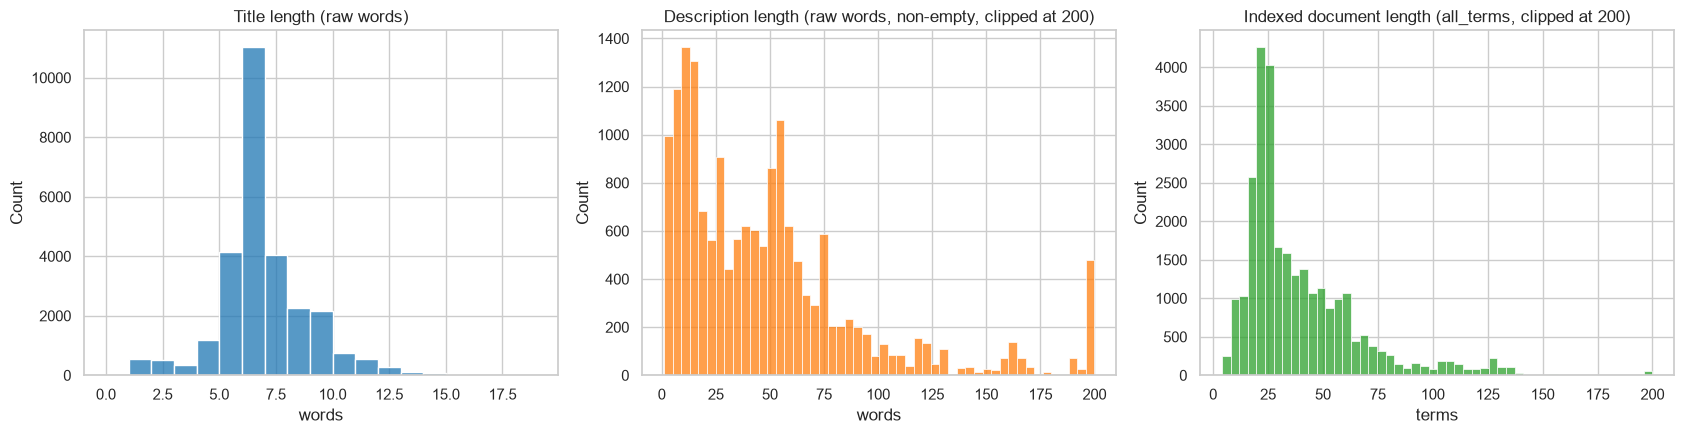

In [97]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df["title_words"], bins=range(0, 20), ax=axes[0], color="tab:blue")
axes[0].set_title("Title length (raw words)")
axes[0].set_xlabel("words")

sns.histplot(df.loc[has_description, "description_words"].clip(upper=200), bins=50, ax=axes[1], color="tab:orange")
axes[1].set_title("Description length (raw words, non-empty, clipped at 200)")
axes[1].set_xlabel("words")

sns.histplot(df["all_n_terms"].clip(upper=200), bins=50, ax=axes[2], color="tab:green")
axes[2].set_title("Indexed document length (all_terms, clipped at 200)")
axes[2].set_xlabel("terms")

plt.tight_layout()
plt.show()

As we can observe from the histograms, most product titles are relatively short and have similar lengths, usually around 6 words.

Descriptions, on the other hand, are much longer and show greater variability. We can also see that approximately 40% of the products have an empty description.

Finally, the processed documents have different lengths depending on the amount of information available in each product. These differences are important because document length can influence the ranking scores, especially when using methods such as TF-IDF and BM25 in the following parts of the project.

## 2.2 Average sentence length

We analyze the average sentence length in product descriptions to better understand how the information is structured.

We use NLTK’s sent_tokenize to split the descriptions into sentences. Since some descriptions contain sentences without a space after the full stop, we correct this before tokenization. Only non-empty descriptions are considered in this analysis.

Number of sentences:                    55323
Average sentences per description:      3.27
Average sentence length (words):        15.16
Median sentence length (words):         14


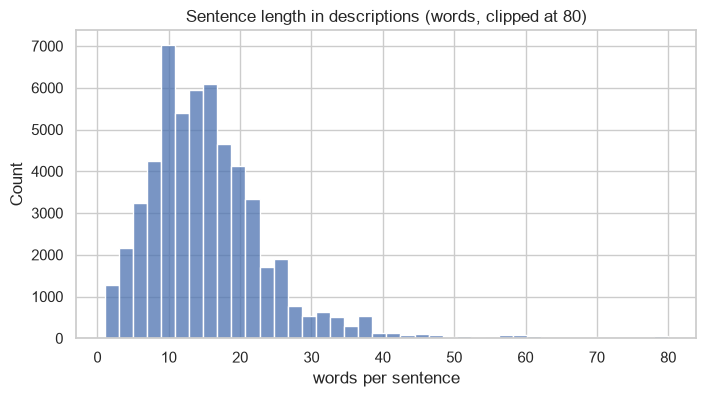

In [68]:
def split_sentences(text):
    """Splits a description into sentences, also when there is no space after the full stop."""
    text = re.sub(r"([.!?])([A-Z])", r"\1 \2", text)  # "look.Designed" -> "look. Designed"
    return sent_tokenize(text)


descriptions = df.loc[has_description, "description"]
sentences = descriptions.apply(split_sentences)
sentence_lengths = [len(s.split()) for sents in sentences for s in sents]

print(f"Number of sentences:                    {len(sentence_lengths)}")
print(f"Average sentences per description:      {sentences.str.len().mean():.2f}")
print(f"Average sentence length (words):        {np.mean(sentence_lengths):.2f}")
print(f"Median sentence length (words):         {np.median(sentence_lengths):.0f}")

plt.figure(figsize=(8, 4))
sns.histplot(np.clip(sentence_lengths, 0, 80), bins=40)
plt.title("Sentence length in descriptions (words, clipped at 80)")
plt.xlabel("words per sentence")
plt.show()

## 2.3 Vocabulary size

We analyze how the vocabulary size changes after each pre-processing step. To do this, we count the number of unique tokens in all product titles and descriptions, starting with the original text and applying each pre-processing step progressively.

This allows us to identify which steps have the greatest impact on reducing the vocabulary.

In [98]:
all_text = (df["title"] + " " + df["description"]).tolist()

vocab_steps = {}
tokens_raw = [t for text in all_text for t in text.split()]
vocab_steps["1. raw (split on spaces)"] = set(tokens_raw)

tokens_lower = [t.lower() for t in tokens_raw]
vocab_steps["2. lowercase"] = set(tokens_lower)

tokens_clean = [t for text in all_text for t in word_tokenize(clean_text(text))]
vocab_steps["3. + clean & punctuation removed"] = set(tokens_clean)

tokens_alpha = [t for t in tokens_clean if t.isalpha() and len(t) > 1]
vocab_steps["4. + numbers / 1-char removed"] = set(tokens_alpha)

tokens_nostop = [t for t in tokens_alpha if t not in STOP_WORDS]
vocab_steps["5. + stop words removed"] = set(tokens_nostop)

tokens_stem = [stemmer.stem(t) for t in tokens_nostop]
vocab_steps["6. + stemming (final)"] = set(tokens_stem)

vocab_table = pd.DataFrame({
    "vocabulary_size": [len(v) for v in vocab_steps.values()],
}, index=vocab_steps.keys())
vocab_table["total_tokens"] = [len(tokens_raw), len(tokens_lower), len(tokens_clean),
                               len(tokens_alpha), len(tokens_nostop), len(tokens_stem)]
vocab_table

,vocabulary_size,total_tokens
1. raw (split on spaces),13521,1017425
2. lowercase,10606,1017425
3. + clean & punctuation removed,6534,1028502
4. + numbers / 1-char removed,6236,984958
5. + stop words removed,6118,687119
6. + stemming (final),4651,687119


In [99]:
vocab_all = Counter(t for terms in df["all_terms"] for t in terms)
print("Vocabulary size of the final index field (all_terms):", len(vocab_all))
print("Terms that appear only once (hapax legomena):", sum(1 for c in vocab_all.values() if c == 1))

Vocabulary size of the final index field (all_terms): 5335
Terms that appear only once (hapax legomena): 1148


The vocabulary goes from 13,521*distinct raw tokens to 4,651 stems (−66%). Stop word removal reduces the number of tokens by ~30% (they are very frequent) but barely the vocabulary (there are only ~180 stop words), while lowercasing, punctuation removal and stemming are the steps that reduce the vocabulary. Punctuation removal slightly *increases* the number of tokens because glued words (*"look.Designed"*) are split. A smaller vocabulary means a smaller inverted index and more matches between query and document variants.

### Zipf's law


Zipf’s law states that the frequency of a word is approximately inversely proportional to its rank (f ∝ 1/rank). This means that a small number of words appear very frequently, while most words occur much less often.

We check whether our dataset follows this pattern by plotting word frequencies against their ranks on a log-log scale.

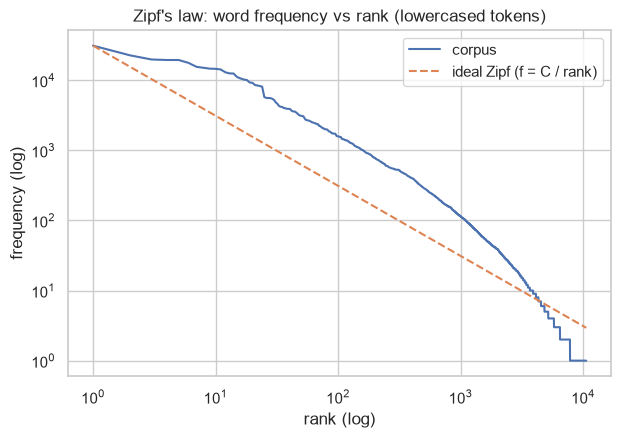

In [100]:
frequencies = sorted(Counter(tokens_lower).values(), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(7, 4.5))
plt.loglog(ranks, frequencies, label="corpus")
plt.loglog(ranks, frequencies[0] / ranks, "--", label="ideal Zipf (f = C / rank)")
plt.xlabel("rank (log)")
plt.ylabel("frequency (log)")
plt.title("Zipf's law: word frequency vs rank (lowercased tokens)")
plt.legend()
plt.show()

The graph shows a decreasing relationship between word frequency and rank, following the general trend described by Zipf’s law.

A small number of words appear very frequently, while most words have much lower frequencies. However, the observed distribution does not perfectly match the theoretical Zipf curve.

This is expected since our dataset contains product descriptions and titles, where certain words are repeated frequently. The presence of common words and many rare terms also supports the importance of stop word removal and text normalization during pre-processing.

## 2.4 Most frequent words and word clouds

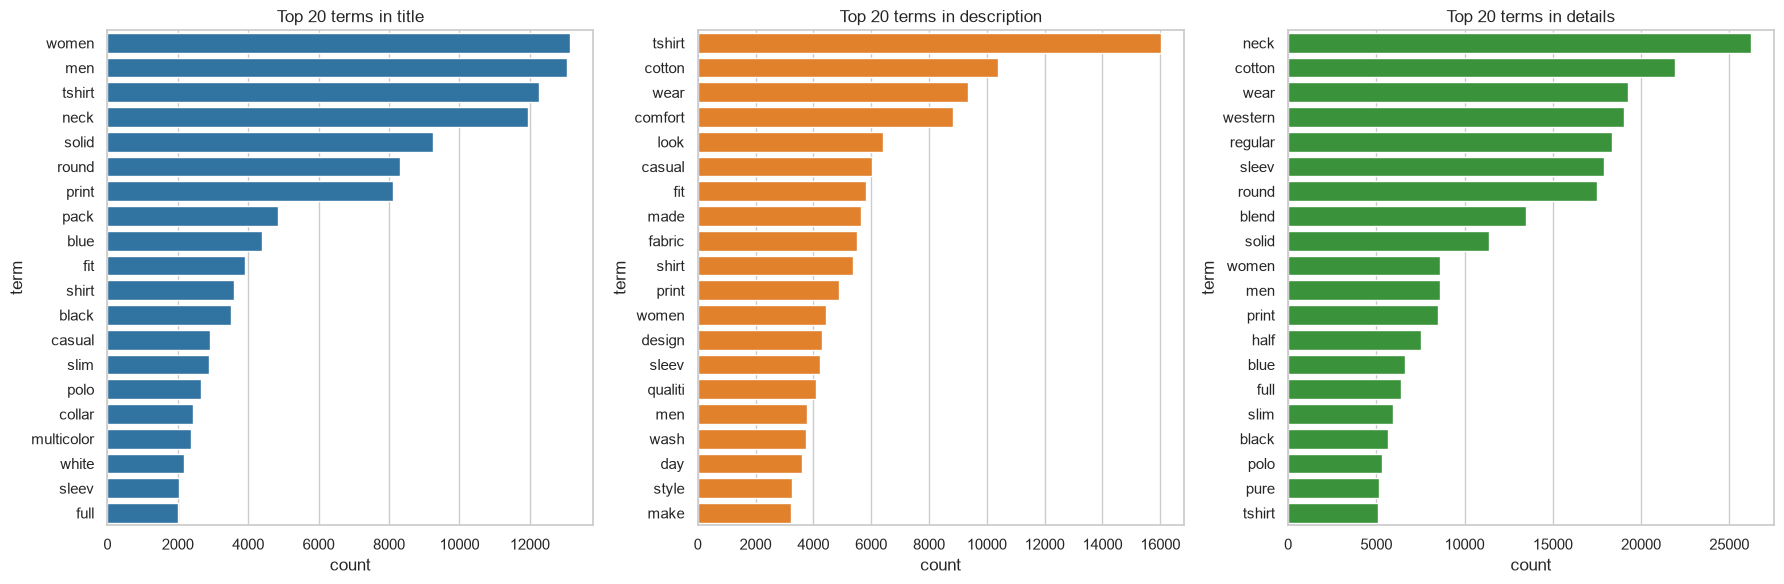

In [102]:
def top_terms(term_lists, n=20):
    """Returns the n most frequent terms in a list of term lists."""
    return Counter(t for terms in term_lists for t in terms).most_common(n)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, field, color in zip(axes, ["title_terms", "description_terms", "details_terms"],
                            ["tab:blue", "tab:orange", "tab:green"]):
    top = pd.DataFrame(top_terms(df[field]), columns=["term", "count"])
    sns.barplot(data=top, y="term", x="count", ax=ax, color=color)
    ax.set_title(f"Top 20 terms in {field.replace('_terms', '')}")
plt.tight_layout()
plt.show()

We also generate word clouds for titles and descriptions to visualize the most frequent words.

For these visualizations, we use the cleaned text without stemming, since the original word forms are easier to interpret.

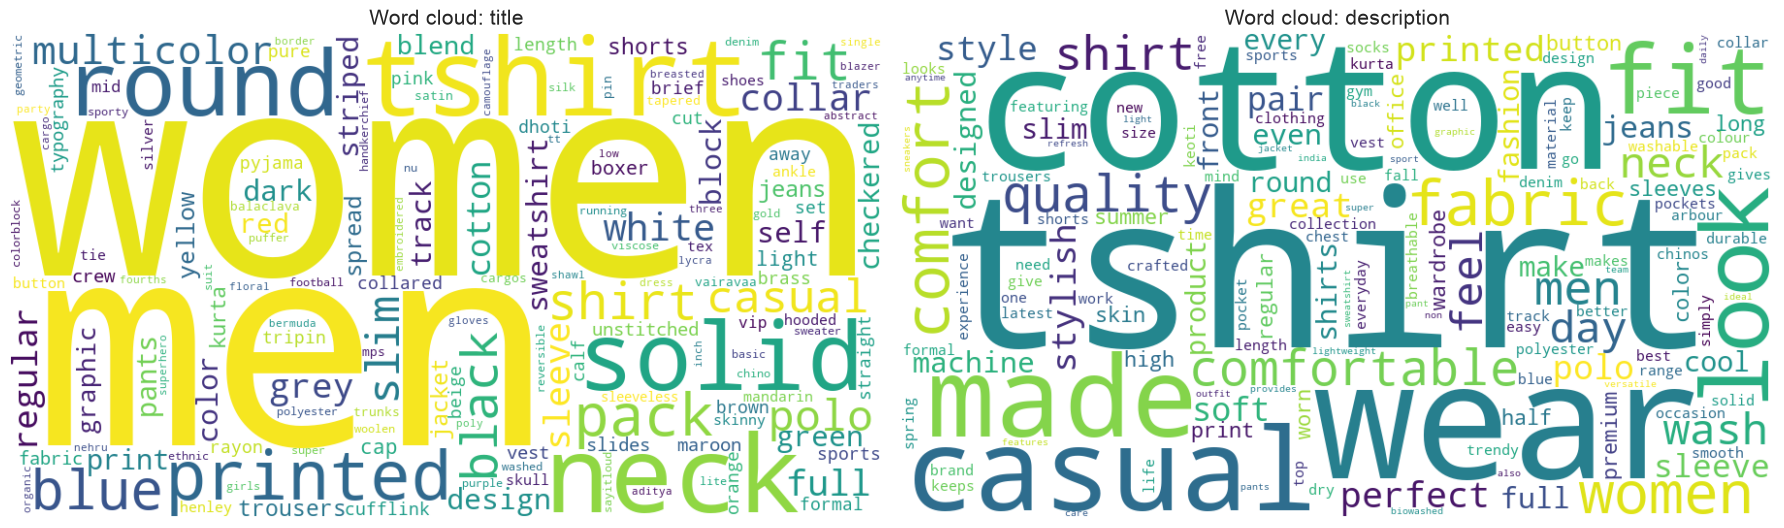

In [103]:
def readable_words(texts):
    """Lowercase words without punctuation, numbers or stop words (no stemming), for word clouds."""
    words = []
    for text in texts:
        for t in word_tokenize(clean_text(text)):
            if t.isalpha() and len(t) > 1 and t not in STOP_WORDS:
                words.append(t)
    return Counter(words)


fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, field in zip(axes, ["title", "description"]):
    cloud = WordCloud(width=900, height=500, background_color="white", colormap="viridis",
                      max_words=150).generate_from_frequencies(readable_words(df[field]))
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"Word cloud: {field}", fontsize=15)
    ax.axis("off")
plt.tight_layout()
plt.show()

Titles are dominated by product type and attribute words (*tshirt, men, women, neck, round, solid, printed, sleeve*), i.e. exactly the vocabulary of the queries. Descriptions contain more marketing language (*comfort, perfect, look, wear, style, quality*), which is less useful to match a specific query and explains why we should give the title (and the details) more weight than the description in the ranking.

## 2.5 Categories and sub-categories

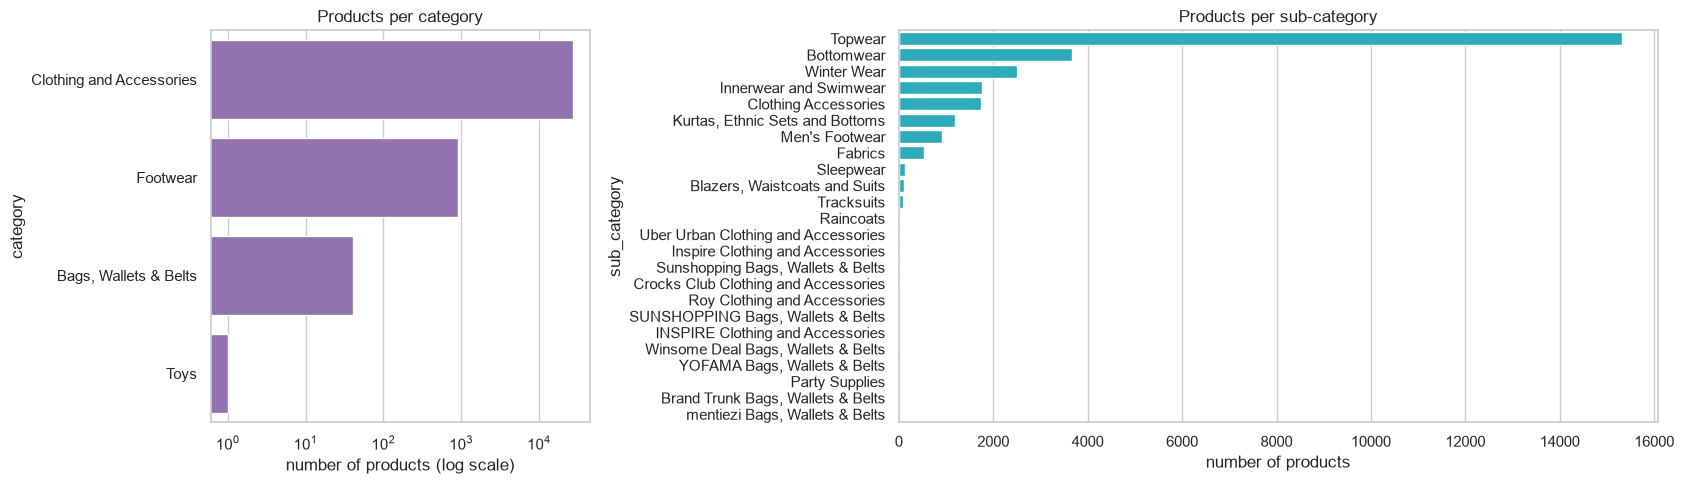

category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64


In [104]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 2]})

cat_counts = df["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0], color="tab:purple")
axes[0].set_title("Products per category")
axes[0].set_xscale("log")
axes[0].set_xlabel("number of products (log scale)")

sub_counts = df["sub_category"].value_counts()
sns.barplot(x=sub_counts.values, y=sub_counts.index, ax=axes[1], color="tab:cyan")
axes[1].set_title("Products per sub-category")
axes[1].set_xlabel("number of products")

plt.tight_layout()
plt.show()
print(cat_counts)

The corpus is very unbalanced: almost all products are clothing and more than half are *Topwear* (t-shirts, shirts, sweatshirts). This supports keeping category out of the text index (it is nearly constant).

## 2.6 Top brands and sellers

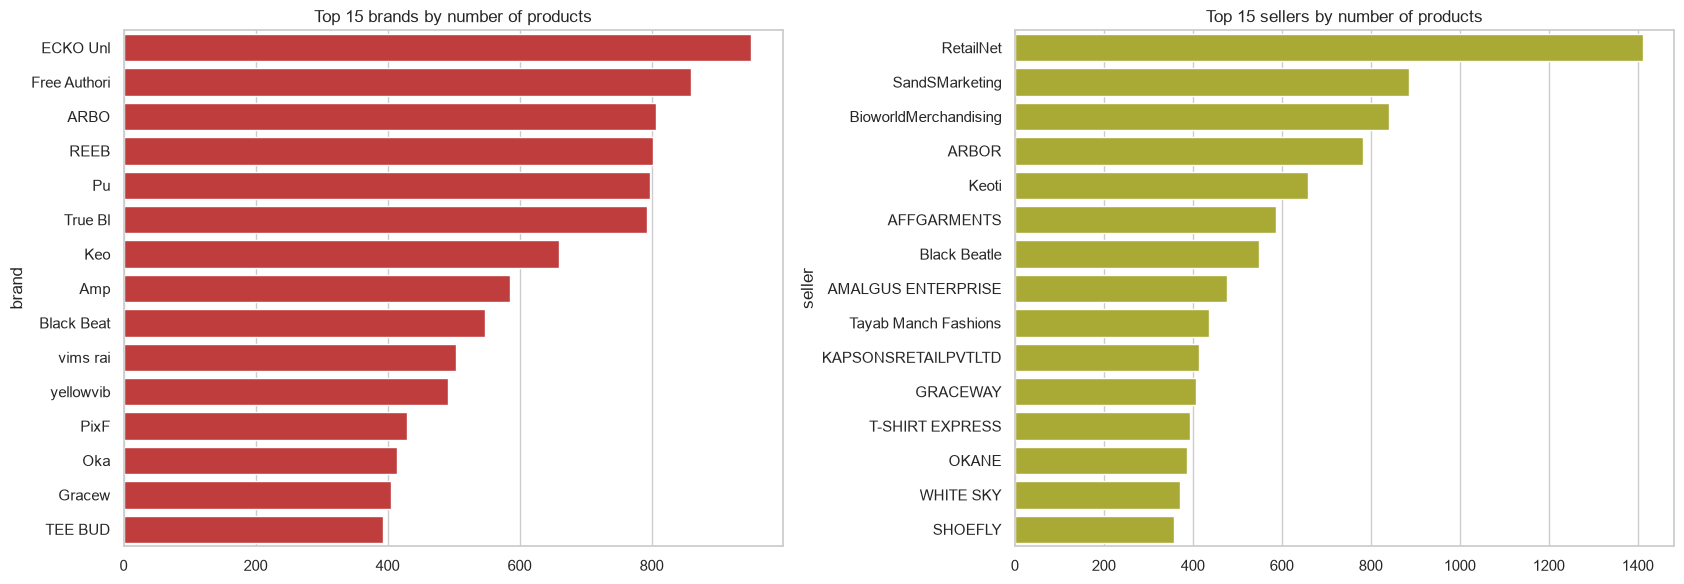

Distinct brands: 324 | products without brand: 2009
Distinct sellers: 534 | products without seller: 1643
The top 10 brands account for 26.0% of all products


In [105]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

top_brands = df.loc[df["brand"] != "", "brand"].value_counts().head(15)
sns.barplot(x=top_brands.values, y=top_brands.index, ax=axes[0], color="tab:red")
axes[0].set_title("Top 15 brands by number of products")

top_sellers = df.loc[df["seller"] != "", "seller"].value_counts().head(15)
sns.barplot(x=top_sellers.values, y=top_sellers.index, ax=axes[1], color="tab:olive")
axes[1].set_title("Top 15 sellers by number of products")

plt.tight_layout()
plt.show()

print("Distinct brands:", df.loc[df["brand"] != "", "brand"].nunique(), "| products without brand:", (df["brand"] == "").sum())
print("Distinct sellers:", df.loc[df["seller"] != "", "seller"].nunique(), "| products without seller:", (df["seller"] == "").sum())
top10_share = 100 * df.loc[df["brand"] != "", "brand"].value_counts().head(10).sum() / len(df)
print(f"The top 10 brands account for {top10_share:.1f}% of all products")

In [108]:
# Get the best rated brands and sellers (only those with at least 50 rated products, to avoid noisy averages)
def best_rated(column, min_products=50, n=10):
    """Best rated values of column (brand or seller) with at least min_products rated products."""
    grouped = df[df[column] != ""].groupby(column).agg(
        products=("pid", "count"),
        rated_products=("average_rating_num", "count"),
        avg_rating=("average_rating_num", "mean"),
        avg_price=("selling_price_num", "mean"),
        avg_discount=("discount_num", "mean"),
    )
    grouped = grouped[grouped["rated_products"] >= min_products]
    return grouped.sort_values("avg_rating", ascending=False).head(n).round(2)


print("Best rated brands (>= 50 rated products):")
display(best_rated("brand"))
print("Best rated sellers (>= 50 rated products):")
display(best_rated("seller"))

Best rated brands (>= 50 rated products):


,products,rated_products,avg_rating,avg_price,avg_discount
brand,,,,,
SORA,74,74,4.61,694.19,61.50
PixF,429,328,4.46,305.03,76.03
Cots,277,277,4.44,356.88,39.19
Zack Fo,128,128,4.33,571.20,62.27
Onei,57,57,4.23,520.74,62.67
Gracew,405,404,4.23,412.07,57.31
Marca Disa,353,334,4.19,582.79,43.60
REEBOK CLASSI,75,75,4.14,1723.51,44.25
Byford by Pantaloo,179,177,4.11,736.54,14.55


Best rated sellers (>= 50 rated products):


,products,rated_products,avg_rating,avg_price,avg_discount
seller,,,,,
SORANG,74,74,4.61,694.19,61.50
EVINCEMARKETERS,320,320,4.48,357.75,38.84
PixFab,309,309,4.46,303.81,76.04
KrishnamEnterprisaes,128,128,4.33,571.20,62.27
GRACEWAY,408,408,4.23,415.41,57.05
Marca Disati,330,330,4.20,581.61,43.36
VAIRAVAA TEX,138,138,4.17,1450.12,38.01
Assiduus Distribution,90,90,4.17,921.99,35.00
RetailNet,1411,1411,4.11,1500.13,41.10


## 2.7 Prices and discounts

In [106]:
df[["selling_price_num", "actual_price_num", "discount_num"]].describe().round(2)

,selling_price_num,actual_price_num,discount_num
count,28078.00,28078.00,28078.00
mean,705.64,1442.79,48.73
std,549.68,940.43,18.73
min,99.00,149.00,0.00
25%,390.00,849.00,37.00
50%,545.00,1199.00,52.00
75%,820.00,1799.00,62.00
max,7999.00,12999.00,87.00


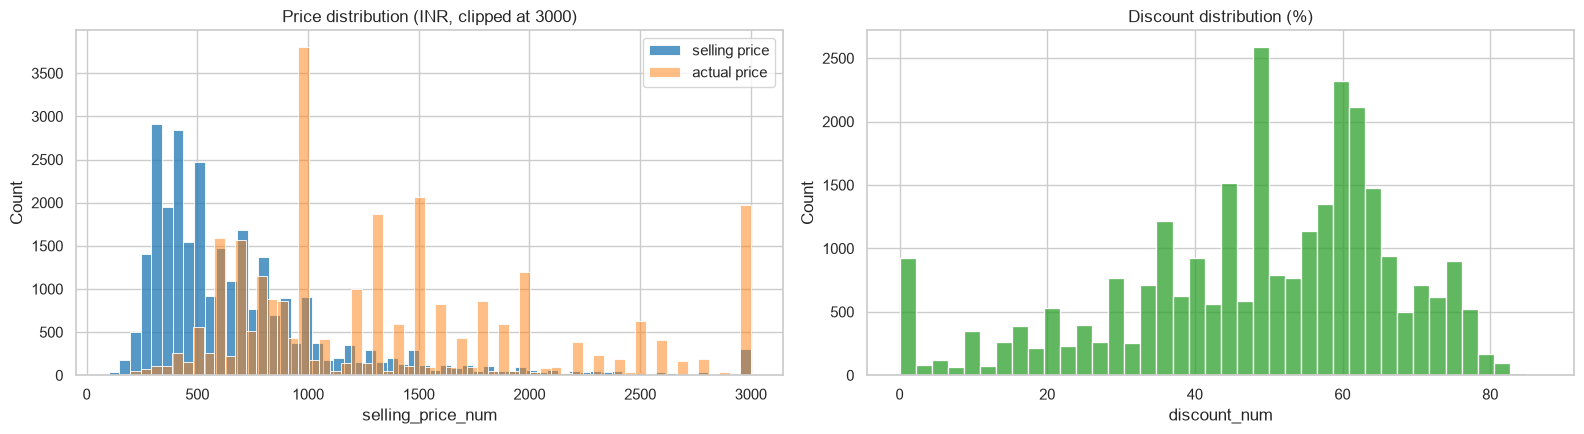

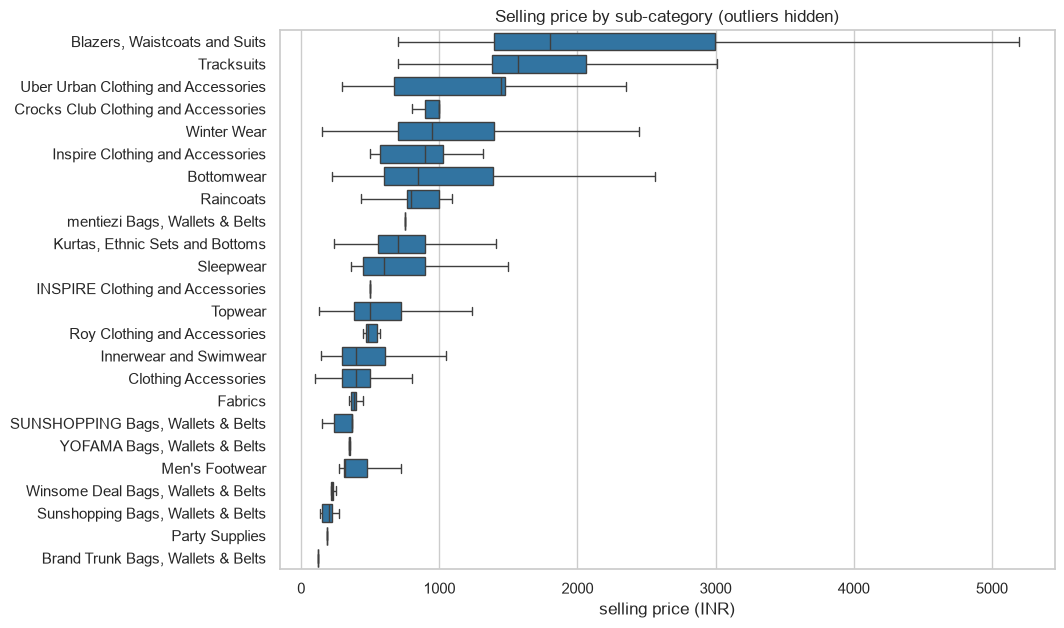

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

sns.histplot(df["selling_price_num"].clip(upper=3000), bins=60, ax=axes[0], color="tab:blue", label="selling price")
sns.histplot(df["actual_price_num"].clip(upper=3000), bins=60, ax=axes[0], color="tab:orange", alpha=0.5, label="actual price")
axes[0].set_title("Price distribution (INR, clipped at 3000)")
axes[0].legend()

sns.histplot(df["discount_num"], bins=40, ax=axes[1], color="tab:green")
axes[1].set_title("Discount distribution (%)")

plt.tight_layout()
plt.show()

order = df.groupby("sub_category")["selling_price_num"].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 7))
sns.boxplot(data=df, y="sub_category", x="selling_price_num", order=order, showfliers=False, color="tab:blue")
plt.title("Selling price by sub-category (outliers hidden)")
plt.xlabel("selling price (INR)")
plt.ylabel("")
plt.show()

The price distributions are strongly right-skewed, indicating that most products are concentrated in the lower price ranges, while a smaller number of products have considerably higher prices. Original prices frequently appear at common retail price points (e.g. 999, 1499, 1999 and 2999 INR). Discounts are also widespread, with many products offering reductions of 50% or more.

The boxplot shows considerable differences in selling prices across sub-categories. Blazers, waistcoats and suits, tracksuits, and winter wear generally have higher prices and greater variability, while categories such as innerwear, fabrics and accessories tend to be more affordable.

However, the boxplot also reveals a data quality issue: some sub_category values contain brand or seller names rather than actual product categories (e.g. “Uber Urban Clothing and Accessories”, “SUNSHOPPING Bags, Wallets & Belts” and “Roy Clothing and Accessories”). This inconsistency makes the field less reliable for text-based retrieval and supports our decision to keep it as a separate attribute rather than merging it into the main searchable text.

These observations also have implications for the ranking system developed in Part 3. Since prices vary considerably between product categories, using raw prices directly in a ranking formula could introduce unwanted biases. A logarithmic transformation or normalization may therefore be appropriate. Additionally, because discounts are common throughout the dataset, a high discount percentage alone may not be a reliable indicator of product quality or relevance.

## 2.8 Ratings

Products with rating: 25819 | without rating: 2261
count    25819.00
mean         3.63
std          0.66
min          1.00
25%          3.20
50%          3.80
75%          4.10
max          5.00
Name: average_rating_num, dtype: float64


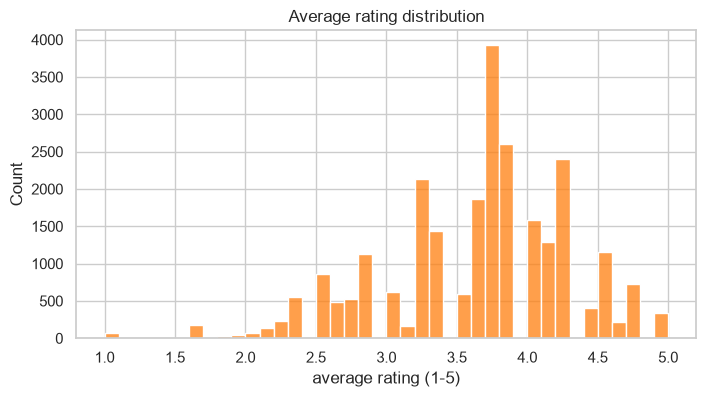

In [109]:
print(f"Products with rating: {df['average_rating_num'].notna().sum()} | without rating: {df['average_rating_num'].isna().sum()}")
print(df["average_rating_num"].describe().round(2))

plt.figure(figsize=(8, 4))
sns.histplot(df["average_rating_num"].dropna(), bins=40, color="tab:orange")
plt.title("Average rating distribution")
plt.xlabel("average rating (1-5)")
plt.show()

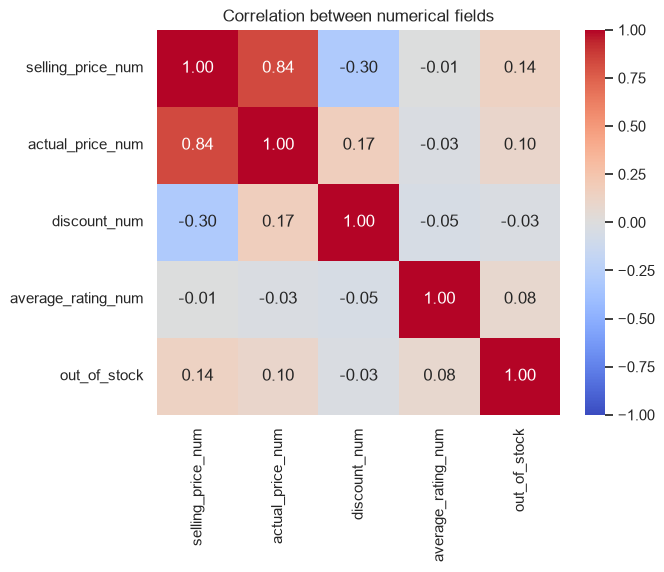

In [110]:
# Correlation between the numerical fields
numeric = df[["selling_price_num", "actual_price_num", "discount_num", "average_rating_num"]].copy()
numeric["out_of_stock"] = df["out_of_stock"].astype(int)

plt.figure(figsize=(6.5, 5))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numerical fields")
plt.show()

## 2.9 Product rankings by rating, price and discount

Many products share the maximum rating of 5.0, so ties are broken by the discount (higher first) and then by the price (lower first). Columns shown are a subset of the output fields.

In [111]:
show_cols = ["pid", "title", "brand", "sub_category", "average_rating_num", "selling_price_num",
             "actual_price_num", "discount_num", "out_of_stock"]

print(f"Products with a perfect 5.0 rating: {(df['average_rating_num'] == 5).sum()}")
print("\nTop 10 products by rating:")
display(df.sort_values(["average_rating_num", "discount_num", "selling_price_num"],
                       ascending=[False, False, True])[show_cols].head(10))

print("Bottom 10 products by rating:")
display(df.dropna(subset=["average_rating_num"]).sort_values("average_rating_num")[show_cols].head(10))

Products with a perfect 5.0 rating: 329

Top 10 products by rating:


,pid,title,brand,sub_category,average_rating_num,selling_price_num,actual_price_num,discount_num,out_of_stock
22441,KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,"Kurtas, Ethnic Sets and Bottoms",5.0,449.0,2599.0,82.0,False
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,Innerwear and Swimwear,5.0,249.0,1149.0,78.0,False
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,Topwear,5.0,275.0,1200.0,77.0,False
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,True
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,True
18714,TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,True
18738,TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,False
18757,TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,False
18781,TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,True
18788,TSHFTT2SWMZ4GA8D,Printed Women Round Neck Black T-Shirt,PixF,Topwear,5.0,288.0,1299.0,77.0,True


Bottom 10 products by rating:


,pid,title,brand,sub_category,average_rating_num,selling_price_num,actual_price_num,discount_num,out_of_stock
15871,BXRFM6KHAZJPYQ9P,Printed Men Boxer (Pack of 2),Urban D,Innerwear and Swimwear,1.0,499.0,1398.0,64.0,False
18444,SRTFKWP6PRBSECMN,"Solid Men White, Blue Sports Shorts",yellowvib,Bottomwear,1.0,540.0,900.0,40.0,True
17722,SOCF2RBXQQT5TSMH,Men Solid Mid-Calf/Crew (Pack of 6),Cots,Clothing Accessories,1.0,360.0,1398.0,74.0,False
17707,SOCEUGUHTNM3FHDW,Women Peds/Footie/No-Show (Pack of 3),Cots,Clothing Accessories,1.0,288.0,599.0,51.0,False
19397,TSHFGJX7ZDYJZUHB,"Color Block Women Round Neck Black, Grey T-Shirt",FLEXIM,Topwear,1.0,399.0,999.0,60.0,False
13935,TSHEKSWUFGNHNVZF,Solid Men Polo Neck White T-Shirt,Scott Internation,Topwear,1.0,898.0,1999.0,55.0,False
16463,SOCECUXJWFZRQD9D,Men Self Design Mid-Calf/Crew,Welwe,Clothing Accessories,1.0,159.0,299.0,46.0,False
19405,TSHFGJX73DGYA27D,"Color Block Men Round Neck Black, Yellow T-Shirt",FLEXIM,Topwear,1.0,399.0,999.0,60.0,False
22502,KTAFAJFFHXVJHUMU,Women Solid Cotton Blend Straight Kurta (Green),Purple Sta,"Kurtas, Ethnic Sets and Bottoms",1.0,494.0,2599.0,80.0,False
18438,TSHFPH8KFPYDG8WP,Printed Men Round Neck Yellow T-Shirt,yellowvib,Topwear,1.0,300.0,999.0,69.0,False


In [112]:
print("Top 10 most expensive products (selling price):")
display(df.sort_values("selling_price_num", ascending=False)[show_cols].head(10))

print("Top 10 cheapest products (selling price):")
display(df.sort_values("selling_price_num")[show_cols].head(10))

print("Top 10 products by discount:")
display(df.sort_values(["discount_num", "average_rating_num"], ascending=False)[show_cols].head(10))

Top 10 most expensive products (selling price):


,pid,title,brand,sub_category,average_rating_num,selling_price_num,actual_price_num,discount_num,out_of_stock
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,Tracksuits,2.7,7999.0,9999.0,20.0,True
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sleeve Blazer (Grey),True Bl,"Blazers, Waistcoats and Suits",2.6,7998.0,7999.0,0.0,False
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,Winter Wear,4.5,7799.0,12999.0,40.0,False
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,Winter Wear,3.7,7799.0,12999.0,40.0,False
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,Bottomwear,4.2,7794.0,12990.0,40.0,False
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full Sleeve Blazer (Blue),True Bl,"Blazers, Waistcoats and Suits",2.6,6998.0,6999.0,0.0,False
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,Bottomwear,4.5,6925.0,10990.0,36.0,False
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,Bottomwear,3.8,6692.0,10990.0,39.0,False
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,Winter Wear,3.7,6499.0,12999.0,50.0,False
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,Bottomwear,NaN,6493.0,9990.0,35.0,True


Top 10 cheapest products (selling price):


,pid,title,brand,sub_category,average_rating_num,selling_price_num,actual_price_num,discount_num,out_of_stock
16485,SOCET7QRNHYG9HHB,Women Mid-Calf/Crew (Pack of 2),Welwe,Clothing Accessories,3.8,99.0,199.0,50.0,False
20435,BDAFUBD2EJHFCRNC,Men Printed Bandana,T10 Spor,Clothing Accessories,2.4,99.0,199.0,50.0,False
7654,SOCFFGA2FYZQBFXT,Women Color Block Ankle Length (Pack of 3),your shopping sto,Clothing Accessories,3.9,118.0,499.0,76.0,False
24438,SOCFZ7GFAZGYZGR7,Men Solid Ankle Length (Pack of 3),ina gro,Clothing Accessories,NaN,120.0,399.0,69.0,False
24437,SOCFZAGJC3VUFQU9,Women Solid Ankle Length (Pack of 3),ina gro,Clothing Accessories,NaN,120.0,399.0,69.0,False
24439,SOCFZ7JX39ZEW8GE,Women Solid Ankle Length (Pack of 3),ina gro,Clothing Accessories,NaN,120.0,399.0,69.0,False
20253,CAPEX5YHPH3MSGFC,Cotton 5 panel baseball Cap,T10 Spor,Clothing Accessories,2.3,124.0,249.0,50.0,False
16402,SUSECSFFVNKG5VGG,Brand Trunk Y- Back Suspenders for Men (Black),,"Brand Trunk Bags, Wallets & Belts",4.1,125.0,499.0,74.0,False
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,Topwear,3.0,128.0,998.0,87.0,False
25325,SOCFPR9UF8Q4FCHG,Men Ankle Length (Pack of 3),Pu,Clothing Accessories,3.7,132.0,499.0,73.0,False


Top 10 products by discount:


,pid,title,brand,sub_category,average_rating_num,selling_price_num,actual_price_num,discount_num,out_of_stock
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,Topwear,3.0,128.0,998.0,87.0,False
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,Topwear,4.7,136.0,999.0,86.0,False
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,Topwear,4.1,136.0,999.0,86.0,True
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvib,Topwear,3.2,449.0,2999.0,85.0,False
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,Topwear,4.6,230.0,1500.0,84.0,False
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,Clothing Accessories,4.3,228.0,1499.0,84.0,False
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,Clothing Accessories,4.3,228.0,1499.0,84.0,False
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,Topwear,4.2,228.0,1499.0,84.0,False
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,Topwear,4.2,282.0,1800.0,84.0,False
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",Fairdea,Topwear,3.8,201.0,1299.0,84.0,False


## 2.10 Out-of-stock distribution

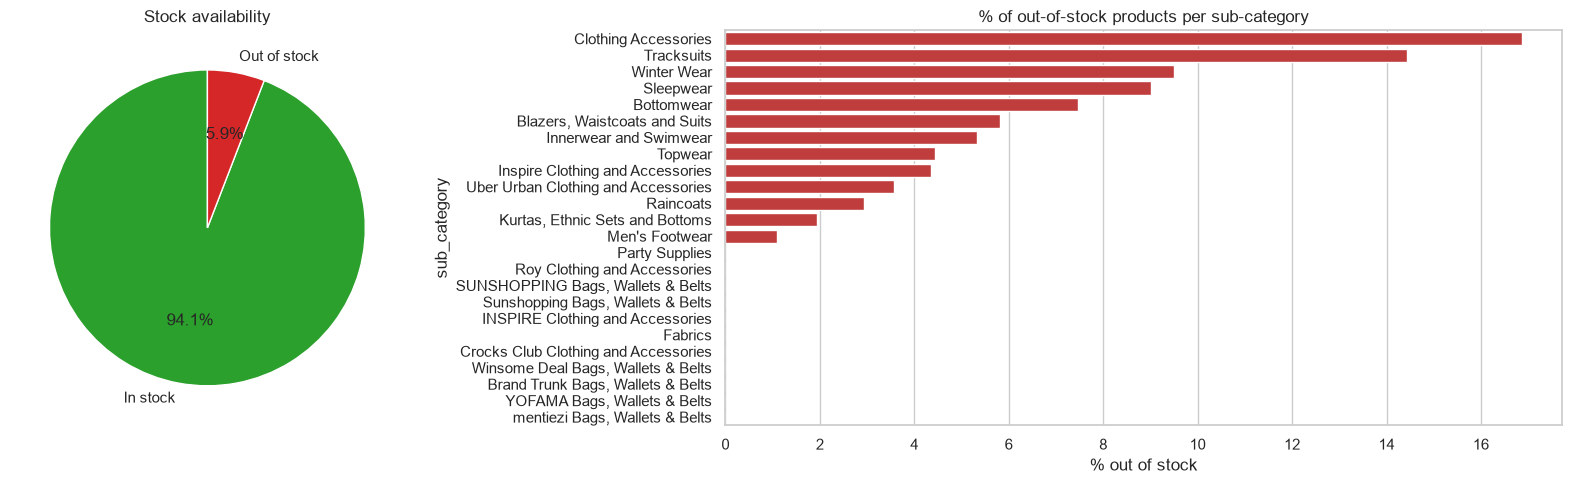

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})

stock = df["out_of_stock"].map({False: "In stock", True: "Out of stock"}).value_counts()
axes[0].pie(stock.values, labels=stock.index, autopct="%1.1f%%", colors=["tab:green", "tab:red"], startangle=90)
axes[0].set_title("Stock availability")

oos_by_sub = (100 * df.groupby("sub_category")["out_of_stock"].mean()).sort_values(ascending=False)
sns.barplot(x=oos_by_sub.values, y=oos_by_sub.index, ax=axes[1], color="tab:red")
axes[1].set_title("% of out-of-stock products per sub-category")
axes[1].set_xlabel("% out of stock")

plt.tight_layout()
plt.show()

In [114]:
# Compare average price, discount and rating between in-stock and out-of-stock products
df.groupby("out_of_stock")[["selling_price_num", "discount_num", "average_rating_num"]].mean().round(2)

,selling_price_num,discount_num,average_rating_num
out_of_stock,,,
False,686.73,48.86,3.62
True,1009.93,46.68,3.92


Only 5.9% of products are out of stock, although availability varies across sub-categories, particularly in Clothing Accessories and Tracksuits.

Out-of-stock products are generally more expensive (1009.93 vs. 686.73 INR), slightly better rated (3.92 vs. 3.62), and have slightly lower discounts.

For our search engine, we keep these products indexed but allow users to filter them out or apply a ranking penalty to prioritize available products.

## 2.11 Product details: fabric, colour, fit, sleeve and target gender



We analyze the most common values of six product attributes (Fabric, Color, Fit, Sleeve, Ideal For and Pattern) to understand their distribution, consistency and usefulness for search.

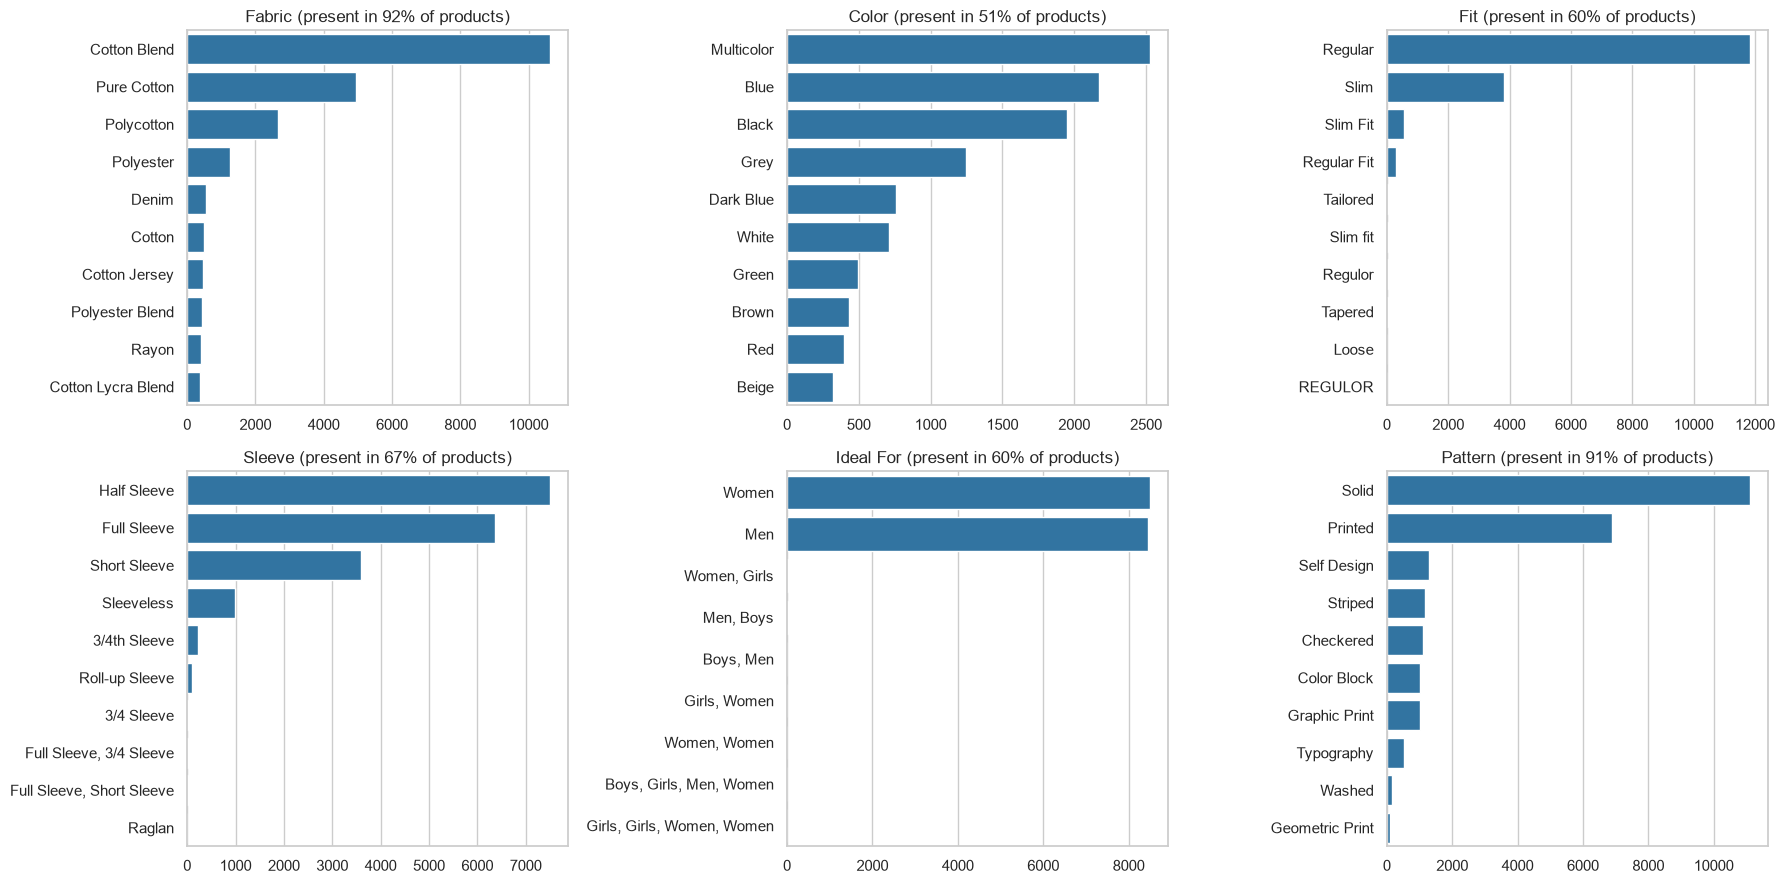

In [85]:
attributes = ["Fabric", "Color", "Fit", "Sleeve", "Ideal For", "Pattern"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, attribute in zip(axes.flatten(), attributes):
    values = df["details_dict"].apply(lambda d: d.get(attribute)).dropna()
    top = values.value_counts().head(10)
    sns.barplot(x=top.values, y=top.index, ax=ax, color="tab:blue")
    ax.set_title(f"{attribute} (present in {100 * len(values) / len(df):.0f}% of products)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Fabric and pattern are present in almost every product, while colour, fit, sleeve and target gender (*Ideal For*) are present in 50-70% of them, so for many products the colour or gender of the item is only in the title. We also see **inconsistent values** for the same concept (*Slim*, *Slim Fit*, *Slim fit*; *Regular*, *Regulor*, *REGULOR*): lowercasing and stemming solve some of them, but typos like *Regulor* would need spelling correction.

## 2.12 Duplicated titles


We saw that there are many fewer distinct titles than products. This matters for search: products with identical titles cannot be told apart by a title-only ranking.

In [86]:
title_counts = df["title"].value_counts()
print(f"Distinct titles: {len(title_counts)} for {len(df)} products")
print(f"Titles shared by more than one product: {(title_counts > 1).sum()}")
print(f"Products whose title is not unique: {title_counts[title_counts > 1].sum()} ({100 * title_counts[title_counts > 1].sum() / len(df):.1f}%)")
print(f"Products with a fully duplicated title + description (non-empty): "
      f"{df[has_description].duplicated(subset=['title', 'description']).sum()}")
pd.DataFrame(title_counts.head(10)).rename(columns={"count": "num_products"})

Distinct titles: 5953 for 28080 products
Titles shared by more than one product: 2335
Products whose title is not unique: 24462 (87.1%)
Products with a fully duplicated title + description (non-empty): 6270


,num_products
title,
Slides,544
Printed Men Round Neck Black T-Shirt,418
Printed Women Round Neck Black T-Shirt,396
Printed Women Round Neck White T-Shirt,349
Rayon Printed Shirt Fabric (Unstitched),343
Printed Men Round Neck White T-Shirt,323
Full Sleeve Solid Men Sweatshirt,214
Full Sleeve Solid Women Sweatshirt,204
Printed Women Round Neck Blue T-Shirt,189


Only 5,953 distinct titles exist among 28,080 products, meaning that 87.1% of products share their title with at least one other product. Additionally, 6,270 products have duplicated titles and non-empty descriptions.

Most titles follow generic templates, making it difficult to distinguish products using only their titles. Therefore, additional ranking signals (ratings, discounts, stock availability and product details) can help differentiate results. Product evaluation must also rely on unique pid identifiers rather than titles.

## 2.13 Named Entity Recognition (NER)


We run the spaCy English model en_core_web_sm on the original (non-preprocessed) descriptions, because NER needs capitalization and punctuation. To keep the runtime reasonable we use a random sample of 3,000 non-empty descriptions.

Entities found: 8447


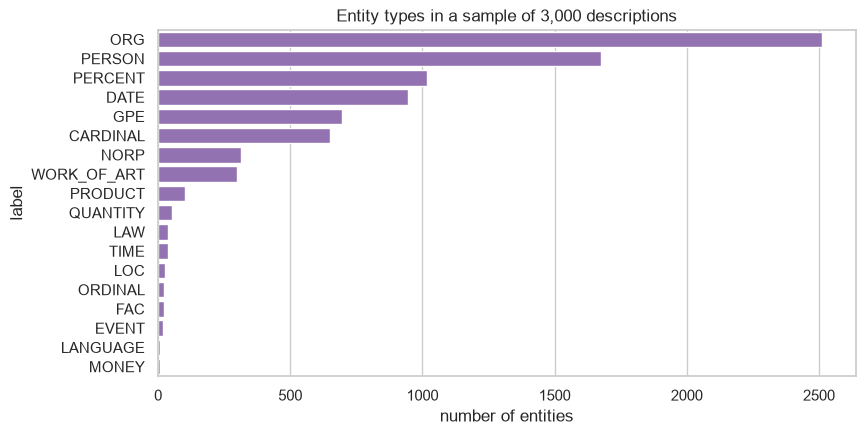

In [115]:
import spacy

try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

sample = df.loc[has_description, "description"].sample(3000, random_state=42)

entities = []
for doc in nlp.pipe(sample, batch_size=200):
    for ent in doc.ents:
        entities.append((ent.text.strip(), ent.label_))

entities_df = pd.DataFrame(entities, columns=["entity", "label"])
print("Entities found:", len(entities_df))
label_counts = entities_df["label"].value_counts()

plt.figure(figsize=(9, 4.5))
sns.barplot(x=label_counts.values, y=label_counts.index, color="tab:purple")
plt.title("Entity types in a sample of 3,000 descriptions")
plt.xlabel("number of entities")
plt.show()

In [117]:
# Display the 8 most frequent entities for each NER category
for label in ["ORG", "GPE", "PERSON", "NORP", "PRODUCT", "CARDINAL", "PERCENT"]:
    top = entities_df[entities_df["label"] == label]["entity"].value_counts().head(8)
    top_text = ", ".join(f"{entity} ({count})" for entity, count in top.items())
    print(f"{label} - {spacy.explain(label)}:\n   {top_text}\n")

ORG - Companies, agencies, institutions, etc.:
   Printed (70), KEOTI (50), Tshirt (48), Round Neck Tees (45), THE AMAZING COMFORT OF A Shoefly POLO T-SHIRTS (43), THE AMAZING COMFORT OF A KEOTI POLO T-SHIRTS (39), Half & Full Sleeve (36), ARBOUR (32)

GPE - Countries, cities, states:
   Cotton (161), kurta (81), Kurta (55), India (53), INDIA (40), Solid (35), Ladies (34), Sweatshirt (21)

PERSON - People, including fictional:
   Casual Wear (77), Track Pant (74), Cotton (61), Arbour (60), Denims (51), Lucky Bird (45), Casual (42), Sweatshirts (41)

NORP - Nationalities or religious or political groups:
   Jeans (112), Joggers (51), Indian (34), Stylish (22), Elastic (13), dhoti (11), Regular (10), Combo (8)

PRODUCT - Objects, vehicles, foods, etc. (not services):
   Round (26), EverLand (12), S-XXL (10), Half Sleeve T-Shirt (6), Shirt (5), MicroModal (5), Exclusive (4), Classic Black And (3)

CARDINAL - Numerals that do not fall under another type:
   half (76), 3 (74), 2 (62), One (

NER finds brand names (ORG), places (GPE, e.g. *India* in "Proudly made in India"), nationalities (NORP) and quantities (CARDINAL, PERCENT such as *100%* cotton). However, the general-purpose model makes many mistakes in this domain: product words in capital letters (*Cotton*, *Regular Fit*) are often tagged as ORG or PERSON. A model trained on news text is not reliable for fashion product descriptions, so NER is interesting to explore the data but we would not use it directly for indexing without a domain-specific model.

## 2.14 Summary of findings

The exploratory analysis of the 28,080 products highlights the following findings and their implications for our search engine:

1. Size and structure: The dataset contains 28,080 products and 17 original fields, with a unique pid for each product. Clothing and Accessories represents 96.6% of the corpus.

2. Text characteristics: Titles are short (6.5 words on average), while 39.7% of descriptions are empty. Product attributes are distributed across titles, descriptions and product_details, making it necessary to combine these fields for retrieval.

3. Vocabulary: Pre-processing reduces the vocabulary from 13,521 raw tokens to 4,651 stems. The final searchable field (all_terms), including product details and brands, contains 5,335 distinct terms.

4. Duplicated titles: Only 5,953 unique titles exist, with 87.1% of products sharing their title with another product. Additional ranking signals can help distinguish products with similar textual content.

5. Brands and sellers: The dataset contains 324 brands and 534 sellers. Some brand names are truncated, and certain sub-categories contain seller names, indicating data quality issues.

6. Prices and discounts: Prices are right-skewed, with a median selling price of 545 INR. Discounts are widespread (48.7% on average), making them less informative as standalone ranking signals.

7. Ratings: The average rating is 3.63, while 8.1% of products have missing ratings. Ratings should be handled carefully, especially when based on few reviews.

8. Stock availability: Only 5.9% of products are out of stock. These products should remain indexed but can be filtered or penalized during ranking.

9. Named Entity Recognition: General-purpose NER identifies some useful entities but frequently misclassifies fashion-related terms, making it unsuitable for direct indexing without further adaptation.

The final processed corpus is saved in processed_corpus.json, containing the cleaned terms, original product information and additional attributes required for filtering and ranking. It is ready for building the inverted index and implementing TF-IDF retrieval in Part 2.

In [116]:
summary = {
    "documents": len(df),
    "empty descriptions (%)": round(100 * (~has_description).mean(), 1),
    "avg title length (words)": round(df["title_words"].mean(), 2),
    "avg description length (words, non-empty)": round(df.loc[has_description, "description_words"].mean(), 2),
    "avg sentence length (words)": round(float(np.mean(sentence_lengths)), 2),
    "raw vocabulary size": len(vocab_steps["1. raw (split on spaces)"]),
    "final vocabulary size (title+description)": len(vocab_steps["6. + stemming (final)"]),
    "final vocabulary size (all_terms)": len(vocab_all),
    "distinct brands": df.loc[df["brand"] != "", "brand"].nunique(),
    "distinct sellers": df.loc[df["seller"] != "", "seller"].nunique(),
    "products without rating (%)": round(100 * df["average_rating_num"].isna().mean(), 1),
    "mean rating": round(df["average_rating_num"].mean(), 2),
    "median selling price (INR)": df["selling_price_num"].median(),
    "mean discount (%)": round(df["discount_num"].mean(), 1),
    "out of stock (%)": round(100 * df["out_of_stock"].mean(), 1),
    "distinct titles": df["title"].nunique(),
}
pd.DataFrame({"metric": list(summary.keys()), "value": [str(v) for v in summary.values()]})

,metric,value
0,documents,28080
1,empty descriptions (%),39.7
2,avg title length (words),6.46
3,"avg description length (words, non-empty)",49.37
4,avg sentence length (words),15.16
5,raw vocabulary size,13521
6,final vocabulary size (title+description),4651
7,final vocabulary size (all_terms),5335
8,distinct brands,324
9,distinct sellers,534
